In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
try:
    df=pd.read_excel('Kidney Disease.xlsx')
except FileNotFoundError:
    print('File Not Found : ')
    exit()
except Exception as e:
    print('Error in Reading Eexcel FIle ',e)

In [3]:
# pd.set_option('display.max_columns', None) 
pd.set_option('display.width', None)

In [4]:
df['target']=df['target'].map({
    1:0,
    0:1
})

In [5]:
df.head()

,age,bp,al,su,rbc,pc,pcc,ba,bgr,bu,...,hemo,pcv,rc,htn,dm,cad,appet,pe,ane,target
0,47,62,2,0,0,0,0,0,167,86,...,9.6,28,2.9,1,1,0,1,0,0,0
1,37,60,0,0,0,0,0,0,114,29,...,16.1,50,5.6,0,0,0,1,0,0,0
2,32,60,0,0,0,0,0,0,108,15,...,14.6,41,5.2,0,0,0,1,1,0,0
3,64,70,1,0,0,0,0,0,101,23,...,16.3,51,5.1,0,0,0,1,0,0,0
4,33,61,0,0,0,0,0,0,95,57,...,12.8,48,4.9,0,0,0,0,0,0,0


In [6]:
df['target'].value_counts()

target
0    6051
1    2263
Name: count, dtype: int64

In [7]:
df.isna().sum()

age       0
bp        0
al        0
su        0
rbc       0
pc        0
pcc       0
ba        0
bgr       0
bu        0
sc        0
hemo      0
pcv       0
rc        0
htn       0
dm        0
cad       0
appet     0
pe        0
ane       0
target    0
dtype: int64

In [8]:
df.columns

Index(['age', 'bp', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc',
       'hemo', 'pcv', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane',
       'target'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8314 entries, 0 to 8313
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     8314 non-null   int64  
 1   bp      8314 non-null   int64  
 2   al      8314 non-null   int64  
 3   su      8314 non-null   int64  
 4   rbc     8314 non-null   int64  
 5   pc      8314 non-null   int64  
 6   pcc     8314 non-null   int64  
 7   ba      8314 non-null   int64  
 8   bgr     8314 non-null   int64  
 9   bu      8314 non-null   int64  
 10  sc      8314 non-null   float64
 11  hemo    8314 non-null   float64
 12  pcv     8314 non-null   int64  
 13  rc      8314 non-null   float64
 14  htn     8314 non-null   int64  
 15  dm      8314 non-null   int64  
 16  cad     8314 non-null   int64  
 17  appet   8314 non-null   int64  
 18  pe      8314 non-null   int64  
 19  ane     8314 non-null   int64  
 20  target  8314 non-null   int64  
dtypes: float64(3), int64(18)
memory usage

In [10]:
df.describe()

,age,bp,al,su,rbc,pc,pcc,ba,bgr,bu,...,hemo,pcv,rc,htn,dm,cad,appet,pe,ane,target
count,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,...,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000,8314.000000
mean,50.570724,74.815853,1.078542,0.376834,0.174645,0.259923,0.137118,0.122685,138.886577,58.771470,...,13.197053,40.458023,4.746356,0.297210,0.258359,0.119557,0.817416,0.194732,0.152514,0.272191
std,15.616020,11.859218,1.524716,0.920670,0.379686,0.438618,0.343993,0.328095,72.079360,52.394115,...,3.087202,9.857751,1.090320,0.457057,0.437759,0.324463,0.386348,0.396018,0.359540,0.445115
min,3.000000,46.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,45.000000,-2.000000,...,2.000000,7.000000,1.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,41.000000,67.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,97.000000,27.000000,...,10.800000,33.000000,4.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
50%,53.000000,78.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,117.000000,42.000000,...,13.900000,43.000000,4.800000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,61.000000,81.000000,3.000000,0.000000,0.000000,1.000000,0.000000,0.000000,140.000000,59.000000,...,15.500000,48.000000,5.500000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
max,89.000000,112.000000,4.000000,5.000000,1.000000,1.000000,1.000000,1.000000,508.000000,324.000000,...,19.000000,57.000000,8.200000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [11]:
df.corr(numeric_only=True)['target']

age       0.187156
bp        0.192374
al        0.498290
su        0.276286
rbc       0.286689
pc        0.393590
pcc       0.250383
ba        0.205403
bgr       0.327799
bu        0.372775
sc        0.387714
hemo     -0.474993
pcv      -0.464894
rc       -0.411582
htn       0.431295
dm        0.379879
cad       0.230255
appet    -0.285268
pe        0.295710
ane       0.251703
target    1.000000
Name: target, dtype: float64

In [12]:
df['htn'].value_counts()

htn
0    5843
1    2471
Name: count, dtype: int64

<Axes: xlabel='target', ylabel='age'>

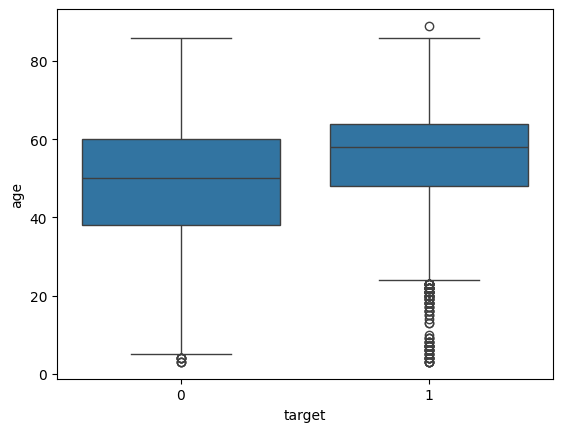

In [13]:
sns.boxplot(df,x='target',y='age')

In [14]:
pd.crosstab(df['target'],df['age'])

age,3,4,5,6,7,8,9,10,11,12,...,78,79,80,81,82,83,84,85,86,89
target,,,,,,,,,,,,,,,,,,,,,
0,3,5,11,5,7,5,4,2,20,3,...,16,17,24,12,15,14,6,3,1,0
1,5,6,4,6,8,4,3,1,0,0,...,2,4,2,1,11,7,4,3,1,1


<Axes: xlabel='age', ylabel='Count'>

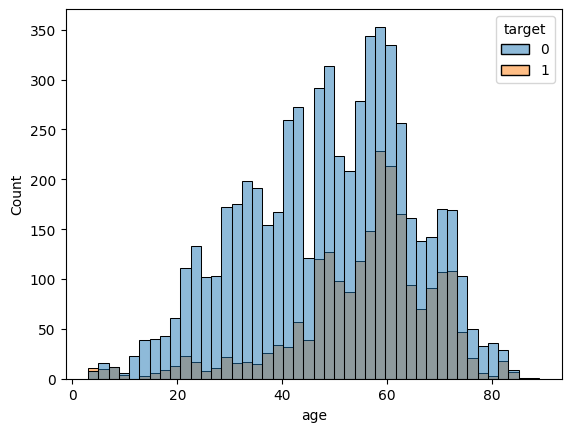

In [15]:
sns.histplot(data=df,x=df['age'],hue='target')

In [16]:
co_relation=df.corr(numeric_only=True)['target']

In [17]:
co_relation.sort_values(ascending=False)

target    1.000000
al        0.498290
htn       0.431295
pc        0.393590
sc        0.387714
dm        0.379879
bu        0.372775
bgr       0.327799
pe        0.295710
rbc       0.286689
su        0.276286
ane       0.251703
pcc       0.250383
cad       0.230255
ba        0.205403
bp        0.192374
age       0.187156
appet    -0.285268
rc       -0.411582
pcv      -0.464894
hemo     -0.474993
Name: target, dtype: float64

In [18]:
df['al'].value_counts()

al
0    5181
4    1047
3    1040
2     613
1     433
Name: count, dtype: int64

<Axes: xlabel='al', ylabel='age'>

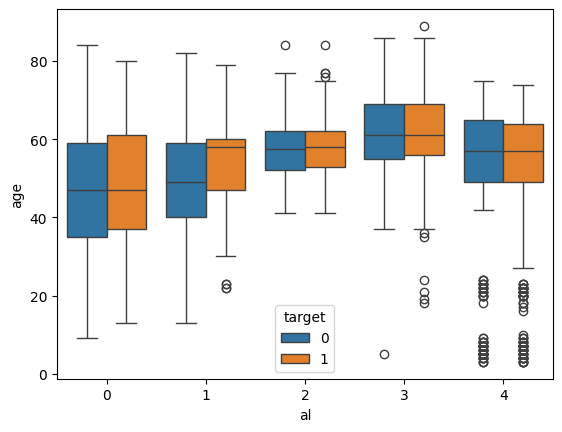

In [19]:
sns.boxplot(df,x='al',y='age',hue='target')

In [20]:
aggregate_value=df.groupby('age')['al'].agg(['mean','min','max','count']).round(0)

In [21]:
aggregate_value.sort_values(by='age',ascending=False)[0:15]

,mean,min,max,count
age,,,,
89,3.0,3,3,1
86,3.0,3,3,2
85,3.0,3,3,6
84,2.0,0,3,10
83,2.0,0,3,21
82,2.0,0,3,26
81,2.0,0,3,13
80,0.0,0,3,26
79,0.0,0,1,21


In [22]:
df['hemo'].value_counts().round()

hemo
13.8    158
14.0    142
15.3    141
14.8    137
13.9    137
       ... 
18.6      1
6.2       1
3.9       1
18.9      1
4.0       1
Name: count, Length: 154, dtype: int64

In [23]:
#There data says hemo is is normal in many young ages but this effecting the old people
df.groupby('age')['hemo'].agg(['mean','std','min','max','count']).round()[0:15]

,mean,std,min,max,count
age,,,,,
3,10.0,0.0,9.0,10.0,8
4,10.0,0.0,9.0,11.0,11
5,10.0,0.0,9.0,10.0,15
6,10.0,0.0,9.0,10.0,11
7,10.0,0.0,10.0,10.0,15
8,10.0,0.0,10.0,10.0,9
9,12.0,3.0,9.0,16.0,7
10,14.0,4.0,9.0,16.0,3
11,16.0,0.0,15.0,16.0,20


<Axes: xlabel='target', ylabel='count'>

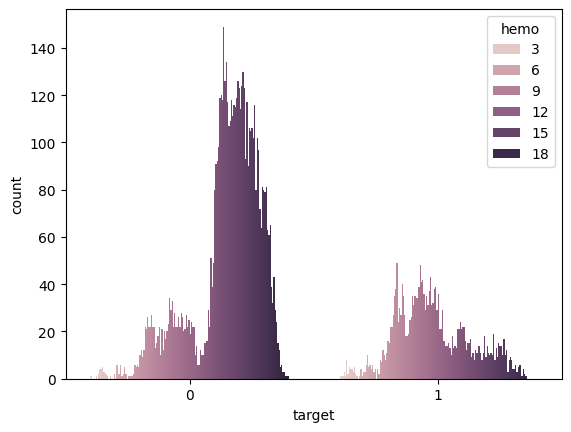

In [24]:
#Low Hemo Increasing the chance of CDK
sns.countplot(df,x='target',hue='hemo')

In [25]:
pd.set_option('display.max_columns', None)
pd.crosstab(df['target'],df['hemo'])

hemo,2.0,2.3,2.4,2.6,2.7,2.8,2.9,3.0,3.1,3.2,3.3,3.4,3.5,3.7,3.8,3.9,4.0,5.0,5.1,5.2,5.3,5.4,5.5,5.6,5.7,5.8,5.9,6.0,6.1,6.2,6.4,6.6,6.7,6.8,6.9,7.0,7.1,7.2,7.3,7.4,7.5,7.6,7.7,7.8,7.9,8.0,8.1,8.2,8.3,8.4,8.5,8.6,8.7,8.8,8.9,9.0,9.1,9.2,9.3,9.4,9.5,9.6,9.7,9.8,9.9,10.0,10.1,10.2,10.3,10.4,10.5,10.6,10.7,10.8,10.9,11.0,11.1,11.2,11.3,11.4,11.5,11.6,11.7,11.8,11.9,12.0,12.1,12.2,12.3,12.4,12.5,12.6,12.7,12.8,12.9,13.0,13.1,13.2,13.3,13.4,13.5,13.6,13.7,13.8,13.9,14.0,14.1,14.2,14.3,14.4,14.5,14.6,14.7,14.8,14.9,15.0,15.1,15.2,15.3,15.4,15.5,15.6,15.7,15.8,15.9,16.0,16.1,16.2,16.3,16.4,16.5,16.6,16.7,16.8,16.9,17.0,17.1,17.2,17.3,17.4,17.5,17.6,17.7,17.8,17.9,18.0,18.1,18.2,18.3,18.4,18.5,18.6,18.9,19.0
target,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1,0,0,0,1,0,2,4,4,5,3,2,2,1,0,1,0,0,2,0,6,2,2,6,1,2,5,2,0,1,1,1,1,2,6,5,6,5,10,12,9,12,22,21,26,22,22,27,22,22,13,15,18,22,10,21,12,20,17,20,23,34,29,33,22,28,22,22,26,22,28,26,20,21,27,22,25,19,24,22,22,10,14,6,6,12,10,10,15,15,16,29,22,51,39,49,80,91,92,98,119,120,118,149,126,134,117,107,109,118,111,116,115,119,126,123,114,124,130,123,93,117,90,106,105,106,102,116,80,102,97,72,64,81,80,79,81,63,61,65,39,32,43,29,24,15,12,5,6,3,3,1,1,1
1,0,1,1,1,3,1,8,2,5,4,4,3,5,2,1,0,1,4,1,3,3,6,10,5,6,4,6,3,4,0,4,2,8,7,12,10,8,11,16,15,22,22,27,35,38,49,24,30,27,40,35,27,18,18,19,25,26,35,31,35,34,34,39,48,41,42,36,29,35,31,37,43,31,32,38,39,29,36,21,21,29,16,16,14,14,15,13,10,18,13,14,13,21,21,24,21,22,22,16,12,15,15,17,9,11,8,12,11,14,14,11,8,11,18,9,14,11,10,11,10,19,8,13,9,15,14,14,10,17,10,12,3,8,9,8,4,4,6,3,5,6,6,1,4,2,1,0,0,0,0,0,0,0,0


In [26]:
#Hemoglobin has lower level in old people whos ages are greater than 35
df[(df['hemo']<=10.0) & (df['target']==1)][['age','hemo']]

,age,hemo
10,70,5.8
14,46,8.6
17,60,7.5
40,67,5.7
48,53,9.6
...,...,...
8272,55,4.0
8282,58,6.7
8293,59,6.8
8298,62,8.8


<Axes: xlabel='pcv', ylabel='Count'>

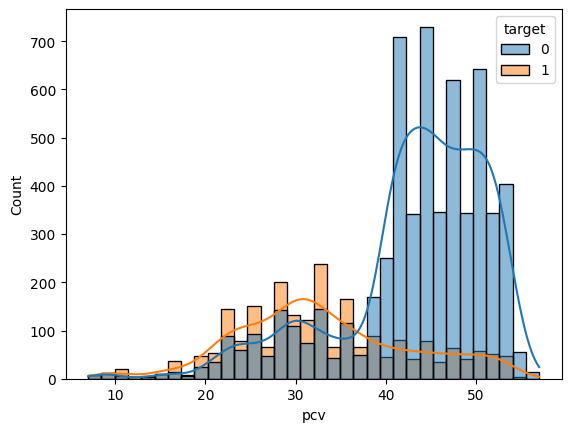

In [27]:
#low pcv increasing the risk of cdk.
sns.histplot(df,x=df['pcv'],hue='target',kde=True)

In [28]:
pd.crosstab(df['target'],df['pcv'])

pcv,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57
target,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,2,6,12,4,2,0,2,1,9,7,7,6,6,18,34,38,50,60,41,51,48,66,77,109,74,70,75,44,60,55,50,51,119,251,350,358,341,388,342,345,304,316,343,306,337,343,237,166,56,13,1
1,1,6,12,18,2,3,0,5,10,23,14,8,11,36,53,66,79,79,78,72,66,85,115,132,122,129,109,65,78,88,65,49,40,46,50,31,40,36,42,35,31,33,41,28,29,52,32,15,3,0,0


In [29]:
pd.crosstab(df['target'],df['pcv'].between(30,40))

pcv,False,True
target,,
0,5093,958
1,1340,923


In [30]:
df.groupby('age')['pcv'].agg({'mean','min','max','count'}).round()

,mean,max,count,min
age,,,,
3,30.0,32,8,28
4,30.0,32,11,28
5,30.0,32,15,29
6,30.0,32,11,28
7,30.0,32,15,28
...,...,...,...,...
83,30.0,50,21,24
84,26.0,38,10,23
85,26.0,27,6,25


In [31]:
pcv_group=df.groupby('age')['pcv'].agg({'mean','min','max','count'}).round()
pcv_group.sort_values(by='min',ascending=True)

,mean,max,count,min
age,,,,
57,39.0,55,250,7
54,38.0,55,190,7
56,38.0,55,242,7
55,38.0,54,207,8
58,37.0,56,292,8
...,...,...,...,...
11,49.0,51,20,47
13,50.0,51,24,47
14,50.0,52,18,48


In [32]:
#Model Implemnetation

In [33]:
df.sample(5)

,age,bp,al,su,rbc,pc,pcc,ba,bgr,bu,sc,hemo,pcv,rc,htn,dm,cad,appet,pe,ane,target
6313,15,80,0,0,0,0,0,0,86,5,1.1,16.4,52,4.8,0,0,0,1,0,0,0
5852,47,57,0,0,0,0,0,0,89,33,0.7,16.5,40,4.8,0,0,0,1,0,0,0
2892,51,83,4,0,0,1,0,0,104,179,7.7,9.9,31,3.2,1,0,0,1,0,1,1
6974,56,80,3,1,0,1,1,1,235,72,4.1,10.6,35,3.5,1,1,0,1,1,0,0
3062,46,62,0,0,0,0,0,0,117,30,0.7,13.0,43,5.5,0,0,0,1,0,0,0


In [34]:
df.columns

Index(['age', 'bp', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc',
       'hemo', 'pcv', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane',
       'target'],
      dtype='object')

In [35]:
from sklearn.model_selection import train_test_split
x=df.drop(columns=['target'])
y=df['target']

In [36]:
# #Undersampling for maing data balacned 
from imblearn.under_sampling import RandomUnderSampler
R_sample=RandomUnderSampler(random_state=42)
x_resem,y_resem=R_sample.fit_resample(x,y)


In [37]:
x_train,x_test,y_train,y_test=train_test_split(x_resem,y_resem,test_size=0.2,random_state=42)


In [38]:
y.value_counts()

target
0    6051
1    2263
Name: count, dtype: int64

In [39]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)


In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [41]:
x_train_scaled

array([[ 0.50245476, -1.41983879, -0.91963686, ...,  0.57054517,
        -0.58500608, -0.50043159],
       [ 0.24092326,  1.25842078,  0.31978437, ...,  0.57054517,
        -0.58500608, -0.50043159],
       [ 1.09090065, -1.10474943, -0.91963686, ...,  0.57054517,
        -0.58500608, -0.50043159],
       ...,
       [ 0.43707189,  1.80982716,  1.55920561, ...,  0.57054517,
        -0.58500608,  1.99827512],
       [-0.34752263, -1.34106645, -0.91963686, ...,  0.57054517,
        -0.58500608, -0.50043159],
       [-0.08599113,  0.39192503, -0.91963686, ...,  0.57054517,
        -0.58500608, -0.50043159]], shape=(3620, 20))

In [42]:
model = {
    'LogisticR': LogisticRegression(max_iter=100, class_weight='balanced'),
    'DecisionTree': DecisionTreeClassifier(class_weight='balanced', max_depth=8),
    'SVM': SVC(probability=True, class_weight='balanced'),
    'RandomForest': RandomForestClassifier(class_weight='balanced')
}

#Class_weight='balanced' force model to look to minorty classes also

In [43]:
Results=[]

In [44]:
x_test_scaled

array([[ 0.50245476,  1.25842078,  1.55920561, ..., -1.75270962,
         1.70938395,  1.99827512],
       [-2.04747742,  0.39192503, -0.91963686, ...,  0.57054517,
        -0.58500608, -0.50043159],
       [ 0.37168901, -1.26229411, -0.91963686, ...,  0.57054517,
        -0.58500608, -0.50043159],
       ...,
       [-0.151374  ,  2.04614418,  0.93949499, ..., -1.75270962,
         1.70938395,  1.99827512],
       [ 0.50245476,  1.80982716,  1.55920561, ...,  0.57054517,
        -0.58500608,  1.99827512],
       [ 0.56783764, -1.34106645, -0.91963686, ...,  0.57054517,
        -0.58500608, -0.50043159]], shape=(906, 20))

In [45]:
from sklearn.metrics import accuracy_score, confusion_matrix,f1_score,classification_report

In [46]:
for name, models in model.items():
    models.fit(x_train_scaled,y_train)
    Training=models.score(x_train_scaled,y_train)
    y_predict=models.predict(x_test_scaled)
    acc=accuracy_score(y_test,y_predict)
    Results.append({
        'Model':name,
        'Traning Score':Training,
        'ACC':acc,
                
    })
    

In [47]:
Results

[{'Model': 'LogisticR',
  'Traning Score': 0.7939226519337017,
  'ACC': 0.8090507726269316},
 {'Model': 'DecisionTree',
  'Traning Score': 0.8185082872928177,
  'ACC': 0.8002207505518764},
 {'Model': 'SVM',
  'Traning Score': 0.7947513812154696,
  'ACC': 0.8101545253863135},
 {'Model': 'RandomForest',
  'Traning Score': 0.9997237569060774,
  'ACC': 0.8024282560706402}]

In [48]:
# LRmodel=LogisticRegression(max_iter=100,class_weight='balanced')
LRmodel=LogisticRegression(max_iter=100)

LRmodel.fit(x_train_scaled,y_train)
LR_pred=LRmodel.predict(x_test_scaled)
print(classification_report(y_test,LR_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.82       480
           1       0.80      0.79      0.80       426

    accuracy                           0.81       906
   macro avg       0.81      0.81      0.81       906
weighted avg       0.81      0.81      0.81       906



In [49]:
SVM=SVC(probability=True,class_weight='balanced')
SVM.fit(x_train_scaled,y_train)
SVM_pred=LRmodel.predict(x_test_scaled)
print(classification_report(y_test,LR_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.82       480
           1       0.80      0.79      0.80       426

    accuracy                           0.81       906
   macro avg       0.81      0.81      0.81       906
weighted avg       0.81      0.81      0.81       906



In [50]:
from sklearn.metrics import accuracy_score,f1_score
for k in range(1,11):
    KNN=KNeighborsClassifier(n_neighbors=k)
    KNN.fit(x_train_scaled,y_train)
    knn_y_pred=KNN.predict(x_test_scaled)
    acc=accuracy_score(y_test,knn_y_pred)
    print(f'{k}KNN Resutls :  {acc}')

1KNN Resutls :  0.6832229580573952
2KNN Resutls :  0.6854304635761589
3KNN Resutls :  0.7439293598233996
4KNN Resutls :  0.7417218543046358
5KNN Resutls :  0.7726269315673289
6KNN Resutls :  0.7770419426048565
7KNN Resutls :  0.782560706401766
8KNN Resutls :  0.7891832229580574
9KNN Resutls :  0.7935982339955849
10KNN Resutls :  0.7902869757174393


In [51]:
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier 
from sklearn.tree import DecisionTreeClassifier

In [52]:
BG_model=BaggingClassifier(
    estimator=RandomForestClassifier(  max_depth=8,min_samples_leaf=5),
    n_estimators=5,
    max_samples=0.8, #%80 Data to Each Model
    bootstrap=True,  
    random_state=42, #Getinf THe same Resutls
    max_features=0.8, #Each Tree Sees 80% Features ALso
    n_jobs=-1, #Force CPU To Work
    oob_score=True #Checks Accuracy automattically 
)

In [53]:
BG_model.fit(x_train_scaled,y_train)

,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",RandomForestC...amples_leaf=5)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",5
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",0.8
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",0.8
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [54]:
print('Ooob_score_OB Score : ',BG_model.oob_score_)

Ooob_score_OB Score :  0.7781767955801105


In [55]:
print('Training Score : ',BG_model.score(x_train_scaled,y_train))
print('Testing Score  : ',BG_model.score(x_test_scaled,y_test))

Training Score :  0.7947513812154696
Testing Score  :  0.8101545253863135


In [56]:
BG_model_RF=BG_model.predict(x_test_scaled)

In [57]:
print(classification_report(y_test,BG_model_RF))

              precision    recall  f1-score   support

           0       0.82      0.83      0.82       480
           1       0.80      0.79      0.80       426

    accuracy                           0.81       906
   macro avg       0.81      0.81      0.81       906
weighted avg       0.81      0.81      0.81       906



In [58]:
y_test

577     1
8074    0
3256    0
356     1
6603    1
       ..
5589    1
4827    1
8099    1
3706    1
7151    1
Name: target, Length: 906, dtype: int64

In [59]:
BG_model_RF

array([1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1,
       0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1,

In [60]:
BG_model_DT=BaggingClassifier(
    estimator=DecisionTreeClassifier(  max_depth=8,
    min_samples_leaf=5),
    n_estimators=100,
    max_samples=0.8, #%80 Data to Each  Model
    bootstrap=True,  
    random_state=42, #Getinf THe same Resutls
    max_features=0.8, #Each Tree Sees 80% Features ALso
    n_jobs=-1, #Force CPU To Work
    oob_score=True, #Checks Accuracy automattically 
   
)

In [61]:
BG_model_DT.fit(x_train_scaled,y_train)


,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...amples_leaf=5)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",100
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",0.8
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",0.8
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [62]:
print('Training Score : ',BG_model_DT.score(x_train_scaled,y_train))
print('Testing Score  : ',BG_model_DT.score(x_test_scaled,y_test))

Training Score :  0.7977900552486188
Testing Score  :  0.8101545253863135


In [63]:
print('Ooob_score_OB Score : ',BG_model_DT.oob_score_)

Ooob_score_OB Score :  0.7933701657458564


In [64]:
BG_model_pred=BG_model_DT.predict(x_test_scaled)

In [65]:
confusion_matrix(y_test,BG_model_pred)

array([[397,  83],
       [ 89, 337]])

In [66]:
print(classification_report(y_test,BG_model_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.82       480
           1       0.80      0.79      0.80       426

    accuracy                           0.81       906
   macro avg       0.81      0.81      0.81       906
weighted avg       0.81      0.81      0.81       906



### Model Trained ON

In [67]:
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

In [68]:
gb_model=GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

In [69]:
gb_model.fit(x_train_scaled,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [70]:
print('Training Score : ',gb_model.score(x_train_scaled,y_train))
print('Testing Score  : ',gb_model.score(x_test_scaled,y_test))

Training Score :  0.8038674033149171
Testing Score  :  0.8079470198675497


In [71]:
gb_pred=gb_model.predict(x_test_scaled)

### Classification Reports

In [72]:
print(classification_report(y_test, gb_pred))

              precision    recall  f1-score   support

           0       0.82      0.82      0.82       480
           1       0.80      0.79      0.79       426

    accuracy                           0.81       906
   macro avg       0.81      0.81      0.81       906
weighted avg       0.81      0.81      0.81       906



In [73]:
xgb_model=XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=None,
    use_label_encoder=False,
    eval_matric='mlogloss',
    random_state=42
)

In [74]:
xgb_model.fit(x_train_scaled,y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [75]:
xgb_pred=xgb_model.predict(x_test_scaled)

In [76]:
print('Training Score : ',xgb_model.score(x_train_scaled,y_train))
print('Testing Score  : ',xgb_model.score(x_test_scaled,y_test))

Training Score :  0.8306629834254143
Testing Score  :  0.8035320088300221


In [77]:
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.81      0.82      0.82       480
           1       0.80      0.78      0.79       426

    accuracy                           0.80       906
   macro avg       0.80      0.80      0.80       906
weighted avg       0.80      0.80      0.80       906



In [78]:
import joblib
# feature_columns=[[
#     'age',
#     'al',
#     'htn',
#     'pc',
#     'sc',
#     'dm',
#     'bu',
#     'bgr',
#     'rc',
#     'pcv',
#     'hemo'
# ]]

In [79]:
joblib.dump(BG_model, "kidney_model.pkl")
joblib.dump(x.columns, "feature_columns.pkl")   # list of column names in training order
joblib.dump(scaler, "scaler.pkl")                     # if you used scaling

['scaler.pkl']

In [80]:
# x.columns